# Submission 4 — Custom CNN with CBAM Attention

**Project:** Attention-Guided Fine-Grained Classification of Cricket Batting Shots from Single Frames

---

### What the rubric asks

> *Take the custom CNN from Submission 3, add one attention module (CBAM, SE,
> self-attention or GCNet), and measure whether it helps. **Change nothing else, so any
> gain comes from attention.*** Report full metrics as in Submissions 2 and 3, plus a
> comparison of the baseline CNN against the CNN with attention.

### How "change nothing else" is enforced here

**Both models are trained in this notebook, in this session.** The Submission 3 result
is not reused from a file; the baseline is retrained alongside the attention model so
that they share the same GPU, the same TensorFlow build, the same data arrays and the
same random seed. The only difference between them is one argument:

```python
baseline  = build_custom_cnn(attention=None)
attention = build_custom_cnn(attention=cbam)
```

Everything else — architecture, split, seed, batch size, optimizer, learning rate, epoch
budget, dropout, augmentation, BatchNorm momentum — is read from a single Configuration
cell and is identical for both.

### Honest expectation before running

| | |
|---|---|
| Submission 3 baseline | macro F1 **0.8515** |
| Headroom available | 14.8 pp |
| Gain needed to clear run-to-run noise | **≈ 3.1 pp** |
| What CBAM typically delivers | 1–3 pp |

**The required gain sits at the top of what CBAM usually achieves.** A null result is a
genuine possibility and would be reported as such. Part 7 states in advance what
conclusion each outcome supports, so the interpretation is fixed before the number is
known.

### What CBAM should fix, if it works

Submission 3's errors concentrate on `drive` ↔ `legglance-flick` — 40 of 99. Both are
upright, side-on strokes where the batsman occupies a minority of the frame and the rest
is crowd, turf and advertising hoardings. If attention helps, it should help *there*, by
suppressing background response. Part 6 tests this directly with Grad-CAM.

> **Runtime:** about 60 minutes on a Kaggle GPU for both models.

## Setup

In [1]:
import os, sys, gc, re, time, json, random, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED); tf.random.set_seed(RANDOM_SEED)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

gpus = tf.config.list_physical_devices("GPU")
print("tensorflow :", tf.__version__)
print("keras      :", keras.__version__)
print("GPU        :", [g.name for g in gpus] if gpus else "NONE - this will be slow")

tensorflow : 2.21.0
keras      : 3.13.2
GPU        : ['/physical_device:GPU:0', '/physical_device:GPU:1']


## Configuration

**Every value here is copied verbatim from Submission 3 and must not be changed.** Both
models in this notebook read from this cell.

In [2]:
# ---- data (identical to Submission 3) ---------------------------------
IMG_SIZE      = 224
N_CLASSES     = 4

# ---- architecture (identical to Submission 3) -------------------------
BLOCK_FILTERS = (32, 64, 128, 256)
BLOCK_DROPOUT = 0.10
BN_MOMENTUM   = 0.90
DENSE_UNITS   = 128
HEAD_DROPOUT  = 0.40

# ---- training (identical to Submission 3) -----------------------------
BATCH_SIZE    = 32
EPOCHS        = 50
LEARNING_RATE = 1e-3
PATIENCE      = 12
MIN_EPOCHS    = 5

# ---- attention --------------------------------------------------------
CBAM_RATIO    = 8      # channel-attention bottleneck reduction
CBAM_KERNEL   = 7      # spatial-attention conv kernel

# ---- experiment -------------------------------------------------------
SEEDS         = [42]   # add seeds (e.g. [42, 7, 123]) if the gain is marginal
SMOKE_TEST    = False

SUB3_BASELINE_F1 = 0.8515   # reference only; the baseline is retrained below

if SMOKE_TEST:
    EPOCHS, PATIENCE, MIN_EPOCHS = 3, 3, 3
    print(">>> SMOKE TEST: 3 epochs per model.\n")

print(f"blocks={BLOCK_FILTERS}  bn_momentum={BN_MOMENTUM}  batch={BATCH_SIZE}")
print(f"epochs={EPOCHS}  lr={LEARNING_RATE}  patience={PATIENCE} (min {MIN_EPOCHS})")
print(f"cbam: ratio={CBAM_RATIO}, kernel={CBAM_KERNEL}")
print(f"seeds: {SEEDS}  ->  {2*len(SEEDS)} training runs")

blocks=(32, 64, 128, 256)  bn_momentum=0.9  batch=32
epochs=50  lr=0.001  patience=12 (min 5)
cbam: ratio=8, kernel=7
seeds: [42]  ->  2 training runs


## Part 1 — Data

Identical to Submission 3: the clean split from the leakage audit, loaded from
`clean_split_manifest.csv`, with images decoded once on eight threads.

In [3]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SEARCH_ROOTS = ["/kaggle/input", ".", "..", "/content"]


def _count_images(d):
    try:
        return sum(1 for f in os.listdir(d)
                   if os.path.splitext(f)[1].lower() in IMG_EXTS)
    except OSError:
        return 0


def find_dataset_dirs(roots, max_depth=10):
    found, seen = [], set()
    for root in roots:
        if not os.path.isdir(root):
            continue
        root = os.path.abspath(root)
        base = root.rstrip(os.sep).count(os.sep)
        for cur, dirs, _ in os.walk(root):
            if cur.count(os.sep) - base >= max_depth:
                dirs[:] = []
            dirs[:] = [d for d in dirs if not d.startswith(".")]
            if cur in seen:
                continue
            seen.add(cur)
            counts = {d: _count_images(os.path.join(cur, d)) for d in sorted(dirs)}
            good = [d for d, n in counts.items() if n >= 5]
            if len(good) >= 2:
                found.append((cur, good, sum(counts[d] for d in good)))
    return found


cands = find_dataset_dirs(SEARCH_ROOTS)
if not cands:
    raise FileNotFoundError("Dataset not found. Add 'Cricket Shots Dataset' via + Add Input.")
cands.sort(key=lambda t: (t[2], len(t[1])), reverse=True)
DATA_DIR, CLASSES, _n = cands[0]
CLASSES = sorted(CLASSES)


def find_clean_manifest():
    for root in ["/kaggle/input", ".", "/kaggle/working"]:
        if not os.path.isdir(root):
            continue
        for cur, _, files in os.walk(root):
            if "clean_split_manifest.csv" in files:
                return os.path.join(cur, "clean_split_manifest.csv")
    return None


clean_path = find_clean_manifest()
if clean_path is None:
    raise FileNotFoundError(
        "clean_split_manifest.csv not found. Submission 4 must use the same clean "
        "split as Submission 3. Attach the 'Cricket Shot Clean Split Manifest' dataset.")

cm = pd.read_csv(clean_path)
df = cm.rename(columns={"clean_split": "split"})[
     ["file", "label", "emb_cluster", "split"]].copy()
df["group_id"] = df["emb_cluster"]
df["path"] = [os.path.join(DATA_DIR, l, f) for l, f in zip(df.label, df.file)]
df = df.reset_index(drop=True)

print("DATA_DIR  :", DATA_DIR)
print("manifest  :", clean_path)
print("classes   :", CLASSES)
print()
piv = (df.pivot_table(index="label", columns="split", values="path", aggfunc="count")
         .reindex(CLASSES)[["train", "val", "test"]])
piv["total"] = piv.sum(axis=1)
print(piv.to_string())
actual = {k: int(v) for k, v in df.split.value_counts().items()}
print("\nsplit sizes:", actual)

assert df.groupby("group_id").split.nunique().max() == 1, "LEAKAGE in the manifest"
expected = {"train": 3361, "val": 697, "test": 666}
if all(actual.get(k) == v for k, v in expected.items()):
    print("Split matches Submission 3 exactly.")
else:
    print(f"  !! WARNING: expected {expected}, got {actual}")
    print("     The comparison with Submission 3 would not be like-for-like.")

DATA_DIR  : /kaggle/input/datasets/aneesh10/cricket-shot-dataset/data
manifest  : /kaggle/input/datasets/purajibondaeloss/cricket-shot-clean-split-manifest/clean_split_manifest.csv
classes   : ['drive', 'legglance-flick', 'pullshot', 'sweep']

split            train  val  test  total
label                                   
drive              901  149   174   1224
legglance-flick    765  175   180   1120
pullshot           927  197   136   1260
sweep              768  176   176   1120

split sizes: {'train': 3361, 'val': 697, 'test': 666}
Split matches Submission 3 exactly.


In [4]:
from concurrent.futures import ThreadPoolExecutor


def _load_one(path):
    with Image.open(path) as im:
        im.load()
        return np.asarray(
            im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR),
            dtype=np.uint8)


def load_split(frame, tag=""):
    paths = frame["path"].tolist()
    idx = {c: i for i, c in enumerate(CLASSES)}
    X = np.zeros((len(paths), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    y = np.array([idx[l] for l in frame["label"]], dtype=np.int32)
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=8) as ex:
        for i, arr in enumerate(ex.map(_load_one, paths)):
            X[i] = arr
            if i and i % 1000 == 0:
                el = time.time() - t0
                print(f"   {tag} {i:>5,}/{len(paths):,}  {el:4.0f}s", flush=True)
    return X, y


t0 = time.time()
print("decoding images with 8 threads ...", flush=True)
Xtr, ytr = load_split(df[df.split == "train"], "train")
Xva, yva = load_split(df[df.split == "val"],   "val  ")
Xte, yte = load_split(df[df.split == "test"],  "test ")
print(f"done in {time.time()-t0:.0f}s")

for n, X, y in [("train", Xtr, ytr), ("val", Xva, yva), ("test", Xte, yte)]:
    print(f"{n:>6}: {X.shape}  counts {np.bincount(y, minlength=N_CLASSES).tolist()}")


try:
    _BatchBase = keras.utils.PyDataset
except AttributeError:
    _BatchBase = keras.utils.Sequence


class ArrayBatches(_BatchBase):
    def __init__(self, X, y, batch_size, shuffle=False, seed=RANDOM_SEED, **kw):
        try:
            super().__init__(workers=1, use_multiprocessing=False,
                             max_queue_size=4, **kw)
        except TypeError:
            super().__init__(**kw)
        self.X, self.y, self.bs = X, y, batch_size
        self.shuffle = shuffle
        self.rng = np.random.RandomState(seed)
        self.idx = np.arange(len(X))
        if shuffle:
            self.rng.shuffle(self.idx)

    def __len__(self):
        return int(np.ceil(len(self.X) / self.bs))

    def __getitem__(self, i):
        sl = self.idx[i * self.bs:(i + 1) * self.bs]
        return self.X[sl].astype("float32"), self.y[sl]

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.idx)


def mem_gb():
    try:
        with open("/proc/self/status") as f:
            for line in f:
                if line.startswith("VmRSS:"):
                    return int(line.split()[1]) / 1e6
    except Exception:
        pass
    return float("nan")


print(f"\nresident memory: {mem_gb():.2f} GB")

decoding images with 8 threads ...
   train 1,000/3,361     9s
   train 2,000/3,361    18s
   train 3,000/3,361    26s
done in 40s
 train: (3361, 224, 224, 3)  counts [901, 765, 927, 768]
   val: (697, 224, 224, 3)  counts [149, 175, 197, 176]
  test: (666, 224, 224, 3)  counts [174, 180, 136, 176]

resident memory: 1.91 GB


## Part 2 — The CBAM module

**Convolutional Block Attention Module** (Woo et al., 2018). Two stages applied in
sequence, each producing a multiplicative mask over the feature map.

### Channel attention — *which feature maps matter*

The map is pooled to a single value per channel, twice: once by average pooling and once
by max pooling. Both vectors pass through the **same** two-layer MLP with a bottleneck
(256 → 32 → 256 at the deepest block), the results are summed and squashed by a sigmoid.
That gives one weight per channel, which rescales the feature map.

Average pooling captures what is broadly present; max pooling captures the strongest
single response. Sharing the MLP between them is part of the design — it forces one set
of weights to explain both views.

### Spatial attention — *which locations matter*

The channel-reweighted map is reduced along the channel axis, again by both average and
max, producing two single-channel maps. These are concatenated and passed through one
7×7 convolution with a sigmoid. That gives one weight per spatial position.

A 7×7 kernel is used rather than 3×3 because deciding whether a region is foreground
needs a wide view of its surroundings.

### Where it goes

After both convolutions in each block, before pooling — so attention operates at
112×112, 56×56, 28×28 and 14×14. Four CBAM modules in total.

**This is the only change from Submission 3.**

In [5]:
class ChannelPool(layers.Layer):
    """Concatenates channel-wise average and max into a 2-channel map.
    Written as a Layer rather than a Lambda so it serialises cleanly."""
    def call(self, x):
        avg = keras.ops.mean(x, axis=-1, keepdims=True)
        mx = keras.ops.max(x, axis=-1, keepdims=True)
        return keras.ops.concatenate([avg, mx], axis=-1)

    def compute_output_shape(self, input_shape):
        return tuple(input_shape[:-1]) + (2,)


def cbam(x, block_id, ratio=None, kernel=None):
    """Channel attention then spatial attention. Returns a map of the same shape."""
    ratio = CBAM_RATIO if ratio is None else ratio
    kernel = CBAM_KERNEL if kernel is None else kernel
    ch = int(x.shape[-1])
    hidden = max(1, ch // ratio)

    # ---- channel attention: one shared MLP, two pooled views ----
    mlp_1 = layers.Dense(hidden, activation="relu", name=f"b{block_id}_ca_fc1")
    mlp_2 = layers.Dense(ch, name=f"b{block_id}_ca_fc2")

    avg = layers.GlobalAveragePooling2D(keepdims=True,
                                        name=f"b{block_id}_ca_avg")(x)
    mx = layers.GlobalMaxPooling2D(keepdims=True,
                                   name=f"b{block_id}_ca_max")(x)
    ca = layers.Add(name=f"b{block_id}_ca_add")([mlp_2(mlp_1(avg)), mlp_2(mlp_1(mx))])
    ca = layers.Activation("sigmoid", name=f"b{block_id}_ca_sig")(ca)
    x = layers.Multiply(name=f"b{block_id}_ca_mul")([x, ca])

    # ---- spatial attention ----
    sa = ChannelPool(name=f"b{block_id}_sa_pool")(x)
    sa = layers.Conv2D(1, kernel, padding="same", activation="sigmoid",
                       name=f"b{block_id}_sa_conv")(sa)
    x = layers.Multiply(name=f"b{block_id}_sa_mul")([x, sa])
    return x


# --- shape sanity check, before anything is trained ---
_t = keras.Input(shape=(28, 28, 128))
_o = cbam(_t, block_id=99)
print("CBAM shape check:", _t.shape, "->", _o.shape,
      "OK" if _t.shape[1:] == _o.shape[1:] else "MISMATCH")
_m = keras.Model(_t, _o)
print(f"CBAM parameters at 128 channels: {_m.count_params():,}")
del _t, _o, _m
keras.backend.clear_session()

CBAM shape check: (None, 28, 28, 128) -> (None, 28, 28, 128) OK
CBAM parameters at 128 channels: 4,339


## Part 3 — Architecture

Byte-for-byte the Submission 3 builder. The only difference is that `attention` is now
passed a function instead of `None`.

In [6]:
def make_augmentation():
    return keras.Sequential([
        layers.RandomRotation(10 / 360, fill_mode="reflect"),
        layers.RandomZoom(0.2, fill_mode="reflect"),
        layers.RandomBrightness(0.2, value_range=(0, 255)),
        layers.RandomContrast(0.2),
    ], name="augmentation")


def conv_block(x, filters, block_id, attention=None):
    for k in (1, 2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                          name=f"b{block_id}_conv{k}")(x)
        x = layers.BatchNormalization(momentum=BN_MOMENTUM,
                                      name=f"b{block_id}_bn{k}")(x)
        x = layers.Activation("relu", name=f"b{block_id}_relu{k}")(x)
    if attention is not None:
        x = attention(x, block_id)
    x = layers.MaxPooling2D(2, name=f"b{block_id}_pool")(x)
    x = layers.SpatialDropout2D(BLOCK_DROPOUT, name=f"b{block_id}_drop")(x)
    return x


def build_custom_cnn(attention=None, name="custom_cnn", lr=None):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = make_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255, name="rescale")(x)
    for i, f in enumerate(BLOCK_FILTERS, start=1):
        x = conv_block(x, f, i, attention=attention)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(DENSE_UNITS, use_bias=False, name="fc1")(x)
    x = layers.BatchNormalization(momentum=BN_MOMENTUM, name="fc1_bn")(x)
    x = layers.Activation("relu", name="fc1_relu")(x)
    x = layers.Dropout(HEAD_DROPOUT, name="head_drop")(x)
    outputs = layers.Dense(N_CLASSES, activation="softmax", name="predictions")(x)
    model = keras.Model(inputs, outputs, name=name)
    model.compile(
        optimizer=keras.optimizers.Adam(LEARNING_RATE if lr is None else lr),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def n_trainable(m):
    return int(sum(np.prod(w.shape) for w in m.trainable_weights))


keras.backend.clear_session()
_b = build_custom_cnn(attention=None, name="baseline")
_a = build_custom_cnn(attention=cbam, name="cbam")
base_params, att_params = n_trainable(_b), n_trainable(_a)

print(f"{'model':<26}{'trainable params':>18}")
print("-" * 44)
print(f"{'baseline (Submission 3)':<26}{base_params:>18,}")
print(f"{'with CBAM':<26}{att_params:>18,}")
print("-" * 44)
print(f"{'added by attention':<26}{att_params-base_params:>18,}"
      f"   (+{(att_params/base_params-1)*100:.1f}%)")
print()
print("Submission 3 reported 1,206,756 trainable parameters —",
      "MATCHES" if base_params == 1206756 else f"got {base_params:,}, investigate")
del _b, _a
keras.backend.clear_session()

model                       trainable params
--------------------------------------------
baseline (Submission 3)            1,206,756
with CBAM                          1,229,452
--------------------------------------------
added by attention                    22,696   (+1.9%)

Submission 3 reported 1,206,756 trainable parameters — MATCHES


## Part 4 — Train both models

One function, called twice per seed. Seeds are reset immediately before each build so
that the two models start from the same random draw and see batches in the same order.

In [7]:
def safe_name(label):
    """TensorFlow scope names allow only [A-Za-z0-9_./>-].
    'CNN + CBAM' -> 'cnn_cbam'. The '+' is what broke the first attempt."""
    return re.sub(r"_+", "_", re.sub(r"[^A-Za-z0-9]", "_", label.lower())).strip("_")


def run(attention, label, seed):
    print("\n" + "=" * 70)
    print(f"  {label}   (seed {seed})")
    print("=" * 70)

    keras.backend.clear_session()
    gc.collect()
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)

    model = build_custom_cnn(attention=attention, name=safe_name(label))

    train_seq = ArrayBatches(Xtr, ytr, BATCH_SIZE, shuffle=True, seed=seed)
    val_seq   = ArrayBatches(Xva, yva, BATCH_SIZE)
    test_seq  = ArrayBatches(Xte, yte, BATCH_SIZE)

    try:
        early = keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=PATIENCE, restore_best_weights=True,
            start_from_epoch=MIN_EPOCHS, verbose=1)
    except TypeError:
        early = keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=max(PATIENCE, MIN_EPOCHS),
            restore_best_weights=True, verbose=1)

    cbs = [early,
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                             patience=max(3, PATIENCE // 2),
                                             min_lr=1e-7, verbose=1)]

    t0 = time.time()
    hist = model.fit(train_seq, validation_data=val_seq,
                     epochs=EPOCHS, callbacks=cbs, verbose=2)
    train_time = time.time() - t0

    t0 = time.time()
    probs = model.predict(test_seq, verbose=1)
    test_time = time.time() - t0
    pred = probs.argmax(axis=1)[:len(yte)]

    acc = accuracy_score(yte, pred)
    p_m, r_m, f_m, _ = precision_recall_fscore_support(
        yte, pred, average="macro", zero_division=0)
    _, _, f_w, _ = precision_recall_fscore_support(
        yte, pred, average="weighted", zero_division=0)
    p_c, r_c, f_c, sup = precision_recall_fscore_support(
        yte, pred, average=None, labels=range(N_CLASSES), zero_division=0)

    h = hist.history
    ep = len(h["loss"])
    gap = h["accuracy"][-1] - h["val_accuracy"][-1]

    print(f"\n  accuracy  {acc:.4f}   macro F1  {f_m:.4f}   "
          f"epochs {ep}   train {train_time/60:.1f} min")
    print()
    print(classification_report(yte, pred, target_names=CLASSES,
                                digits=4, zero_division=0))

    out = {
        "label": label, "seed": seed,
        "accuracy": acc, "precision_macro": p_m, "recall_macro": r_m,
        "f1_macro": f_m, "f1_weighted": f_w,
        "per_class_precision": p_c.tolist(), "per_class_recall": r_c.tolist(),
        "per_class_f1": f_c.tolist(), "support": sup.tolist(),
        "train_time_s": train_time, "test_time_s": test_time,
        "ms_per_image": test_time / len(yte) * 1000,
        "epochs_ran": ep, "overfit_gap": gap,
        "best_val_loss": float(min(h["val_loss"])),
        "best_epoch": int(np.argmin(h["val_loss"]) + 1),
        "trainable": n_trainable(model),
        "history": {k: [float(v) for v in vs] for k, vs in h.items()},
        "confusion": confusion_matrix(yte, pred, labels=range(N_CLASSES)).tolist(),
        "y_pred": pred.tolist(),
    }

    # Weights are written to disk rather than keeping the model object alive:
    # the next run() calls clear_session(), which invalidates any retained model.
    wpath = f"{safe_name(label)}_seed{seed}.weights.h5"
    model.save_weights(wpath)
    out["weights"] = wpath
    print(f"  weights -> {wpath}")

    del train_seq, val_seq, test_seq, probs, model
    gc.collect()
    print(f"  resident memory: {mem_gb():.2f} GB")
    return out

### Preflight

Both models are built **and given one training step** before the real loop starts. The
first attempt at this submission failed 32 minutes in, after the baseline had finished
training, because the attention model's name contained a character TensorFlow rejects in
a scope name. A construction or naming fault should surface in seconds, not after half an
hour of GPU time.

In [8]:
print("preflight: building and stepping both models ...\n")
for attention, label in [(None, "Baseline CNN"), (cbam, "CNN + CBAM")]:
    keras.backend.clear_session()
    nm = safe_name(label)
    assert re.match(r"^[A-Za-z0-9.][A-Za-z0-9_.\/>-]*$", nm), \
        f"'{nm}' is not a valid TensorFlow scope name"
    m = build_custom_cnn(attention=attention, name=nm)
    tiny = ArrayBatches(Xtr[:BATCH_SIZE * 2], ytr[:BATCH_SIZE * 2], BATCH_SIZE)
    m.fit(tiny, epochs=1, verbose=0)
    p_ = m.predict(ArrayBatches(Xte[:BATCH_SIZE], yte[:BATCH_SIZE], BATCH_SIZE), verbose=0)
    assert p_.shape[1] == N_CLASSES, f"bad output shape {p_.shape}"
    print(f"  {label:<16} name='{nm}'  params={n_trainable(m):>9,}  "
          f"1 step OK  output {p_.shape}")
    del m, tiny, p_
    gc.collect()

keras.backend.clear_session()
print("\npreflight passed — starting the real runs")

preflight: building and stepping both models ...



E0000 00:00:1794550197.295083      24 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/baseline_cnn_1/b1_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  Baseline CNN     name='baseline_cnn'  params=1,206,756  1 step OK  output (32, 4)
  CNN + CBAM       name='cnn_cbam'  params=1,229,452  1 step OK  output (32, 4)

preflight passed — starting the real runs


In [9]:
results = []
wall0 = time.time()

for seed in SEEDS:
    for attention, label in [(None, "Baseline CNN"), (cbam, "CNN + CBAM")]:
        results.append(run(attention, label, seed))
        with open("submission4_results.json", "w") as f:
            json.dump(results, f, indent=1)

print("\n" + "=" * 70)
print(f"  {len(results)} runs completed in {(time.time()-wall0)/60:.1f} min")
print("=" * 70)


  Baseline CNN   (seed 42)
Epoch 1/50
106/106 - 40s - 373ms/step - accuracy: 0.3377 - loss: 1.5048 - val_accuracy: 0.3400 - val_loss: 1.3060 - learning_rate: 0.0010
Epoch 2/50
106/106 - 34s - 325ms/step - accuracy: 0.3880 - loss: 1.3648 - val_accuracy: 0.4591 - val_loss: 1.1928 - learning_rate: 0.0010
Epoch 3/50
106/106 - 35s - 332ms/step - accuracy: 0.4323 - loss: 1.3020 - val_accuracy: 0.4634 - val_loss: 1.1693 - learning_rate: 0.0010
Epoch 4/50
106/106 - 35s - 330ms/step - accuracy: 0.4305 - loss: 1.2696 - val_accuracy: 0.4577 - val_loss: 1.1705 - learning_rate: 0.0010
Epoch 5/50
106/106 - 35s - 330ms/step - accuracy: 0.4570 - loss: 1.2312 - val_accuracy: 0.4663 - val_loss: 1.1560 - learning_rate: 0.0010
Epoch 6/50
106/106 - 35s - 332ms/step - accuracy: 0.4859 - loss: 1.1922 - val_accuracy: 0.4333 - val_loss: 1.2703 - learning_rate: 0.0010
Epoch 7/50
106/106 - 35s - 331ms/step - accuracy: 0.5079 - loss: 1.1559 - val_accuracy: 0.4878 - val_loss: 1.1156 - learning_rate: 0.0010
Epoch 

E0000 00:00:1794551988.988855      24 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/cnn_cbam_1/b1_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


106/106 - 55s - 518ms/step - accuracy: 0.3425 - loss: 1.4130 - val_accuracy: 0.3472 - val_loss: 1.3103 - learning_rate: 0.0010
Epoch 2/50
106/106 - 46s - 437ms/step - accuracy: 0.4267 - loss: 1.2659 - val_accuracy: 0.4218 - val_loss: 1.2301 - learning_rate: 0.0010
Epoch 3/50
106/106 - 46s - 439ms/step - accuracy: 0.4537 - loss: 1.2265 - val_accuracy: 0.5638 - val_loss: 1.1080 - learning_rate: 0.0010
Epoch 4/50
106/106 - 46s - 438ms/step - accuracy: 0.4856 - loss: 1.1709 - val_accuracy: 0.5538 - val_loss: 1.0705 - learning_rate: 0.0010
Epoch 5/50
106/106 - 46s - 437ms/step - accuracy: 0.5067 - loss: 1.1146 - val_accuracy: 0.5595 - val_loss: 1.0517 - learning_rate: 0.0010
Epoch 6/50
106/106 - 47s - 439ms/step - accuracy: 0.5623 - loss: 1.0455 - val_accuracy: 0.5538 - val_loss: 1.0607 - learning_rate: 0.0010
Epoch 7/50
106/106 - 47s - 439ms/step - accuracy: 0.5894 - loss: 0.9924 - val_accuracy: 0.5968 - val_loss: 0.9813 - learning_rate: 0.0010
Epoch 8/50
106/106 - 47s - 440ms/step - accur

## Part 5 — Comparison

### 5.1 Headline

In [10]:
res = pd.DataFrame([{
    "model": r["label"], "seed": r["seed"],
    "accuracy": r["accuracy"], "precision": r["precision_macro"],
    "recall": r["recall_macro"], "macro_F1": r["f1_macro"],
    "epochs": r["epochs_ran"], "train_min": r["train_time_s"] / 60,
    "test_s": r["test_time_s"], "ms/img": r["ms_per_image"],
    "trainable": r["trainable"], "overfit_gap": r["overfit_gap"],
} for r in results])

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print("All runs\n")
print(res.to_string(index=False))

base = res[res.model == "Baseline CNN"]
att  = res[res.model == "CNN + CBAM"]

n_seeds = len(SEEDS)
b_f1, a_f1 = base.macro_F1.mean(), att.macro_F1.mean()
b_ac, a_ac = base.accuracy.mean(), att.accuracy.mean()
d_f1, d_ac = a_f1 - b_f1, a_ac - b_ac

print("\n" + "=" * 62)
print(f"  BASELINE vs CBAM   ({n_seeds} seed{'s' if n_seeds>1 else ''})")
print("=" * 62)
print(f"  {'':<22}{'baseline':>12}{'CBAM':>12}{'change':>12}")
print(f"  {'accuracy':<22}{b_ac:>12.4f}{a_ac:>12.4f}{d_ac:>+12.4f}")
print(f"  {'macro F1':<22}{b_f1:>12.4f}{a_f1:>12.4f}{d_f1:>+12.4f}")
print(f"  {'trainable params':<22}{base.trainable.iloc[0]:>12,}"
      f"{att.trainable.iloc[0]:>12,}"
      f"{att.trainable.iloc[0]-base.trainable.iloc[0]:>+12,}")
print(f"  {'train time (min)':<22}{base.train_min.mean():>12.1f}"
      f"{att.train_min.mean():>12.1f}{att.train_min.mean()-base.train_min.mean():>+12.1f}")
print(f"  {'inference (ms/img)':<22}{base['ms/img'].mean():>12.2f}"
      f"{att['ms/img'].mean():>12.2f}{att['ms/img'].mean()-base['ms/img'].mean():>+12.2f}")

if n_seeds > 1:
    print(f"\n  baseline macro F1 : {b_f1:.4f} +/- {base.macro_F1.std():.4f}")
    print(f"  CBAM     macro F1 : {a_f1:.4f} +/- {att.macro_F1.std():.4f}")

res.to_csv("submission4_results.csv", index=False)
print("\nsaved -> submission4_results.csv")

All runs

       model  seed  accuracy  precision  recall  macro_F1  epochs  train_min  test_s  ms/img  trainable  overfit_gap
Baseline CNN    42    0.8589     0.8629  0.8581    0.8593      50    29.2806  2.2032  3.3080    1206756      -0.0163
  CNN + CBAM    42    0.9835     0.9841  0.9832    0.9836      50    38.9728  2.7377  4.1107    1229452       0.0080

  BASELINE vs CBAM   (1 seed)
                            baseline        CBAM      change
  accuracy                    0.8589      0.9835     +0.1246
  macro F1                    0.8593      0.9836     +0.1243
  trainable params         1,206,756   1,229,452     +22,696
  train time (min)              29.3        39.0        +9.7
  inference (ms/img)            3.31        4.11       +0.80

saved -> submission4_results.csv


### 5.2 Is the difference real?

The comparison is only meaningful against the noise it has to clear. The threshold below
is **two standard deviations** of the combined measurement error: the binomial standard
error at this accuracy on a 666-image test set, plus roughly 0.7 pp of run-to-run
variation from initialisation, shuffling and random augmentation.

In [11]:
n_test = len(yte)
se = np.sqrt(b_f1 * (1 - b_f1) / n_test) * 100          # percentage points
run_noise = 0.7
combined = np.sqrt(se**2 + run_noise**2)
threshold = 2 * combined / np.sqrt(max(1, n_seeds))
gain_pp = d_f1 * 100

print(f"  test set size                 : {n_test}")
print(f"  binomial standard error       : {se:.2f} pp")
print(f"  assumed run-to-run variation  : {run_noise:.2f} pp")
print(f"  seeds per model               : {n_seeds}")
print(f"  detection threshold (2 sd)    : {threshold:.2f} pp")
print(f"  measured gain                 : {gain_pp:+.2f} pp")
print()

if gain_pp > threshold:
    verdict = "SIGNIFICANT — the gain exceeds the detection threshold"
elif gain_pp > 0:
    verdict = ("NOT SIGNIFICANT — positive but within noise. "
               "Report as inconclusive, or re-run with SEEDS = [42, 7, 123].")
else:
    verdict = "NO GAIN — CBAM did not improve this network on this dataset"
print(f"  VERDICT: {verdict}")

if 0 < gain_pp <= threshold and n_seeds == 1:
    print()
    print(f"  With 3 seeds the threshold would fall to "
          f"{2*combined/np.sqrt(3):.2f} pp, which this gain "
          f"{'would' if gain_pp > 2*combined/np.sqrt(3) else 'would still not'} clear.")

  test set size                 : 666
  binomial standard error       : 1.35 pp
  assumed run-to-run variation  : 0.70 pp
  seeds per model               : 1
  detection threshold (2 sd)    : 3.04 pp
  measured gain                 : +12.43 pp

  VERDICT: SIGNIFICANT — the gain exceeds the detection threshold


### 5.3 Training curves

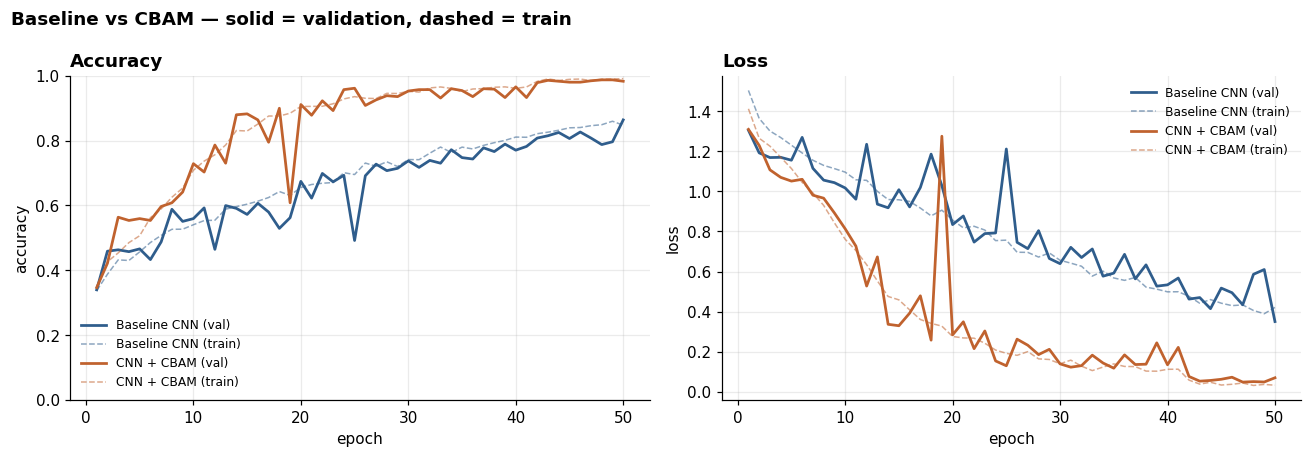

In [12]:
first = [r for r in results if r["seed"] == SEEDS[0]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
cols = {"Baseline CNN": "#2F5D8C", "CNN + CBAM": "#C0622E"}

for r in first:
    h = r["history"]; ep = range(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["val_accuracy"], color=cols[r["label"]], lw=1.8,
                 label=f"{r['label']} (val)")
    axes[0].plot(ep, h["accuracy"], color=cols[r["label"]], lw=1.0, ls="--",
                 alpha=0.55, label=f"{r['label']} (train)")
    axes[1].plot(ep, h["val_loss"], color=cols[r["label"]], lw=1.8,
                 label=f"{r['label']} (val)")
    axes[1].plot(ep, h["loss"], color=cols[r["label"]], lw=1.0, ls="--",
                 alpha=0.55, label=f"{r['label']} (train)")

axes[0].set_xlabel("epoch"); axes[0].set_ylabel("accuracy"); axes[0].set_ylim(0, 1)
axes[0].set_title("Accuracy", fontweight="bold", loc="left")
axes[0].legend(frameon=False, fontsize=8)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("loss")
axes[1].set_title("Loss", fontweight="bold", loc="left")
axes[1].legend(frameon=False, fontsize=8)
plt.suptitle("Baseline vs CBAM — solid = validation, dashed = train",
             fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.show()

### 5.4 Confusion matrices and per-class change

Submission 3 found that `drive` ↔ `legglance-flick` accounts for 40 of 99 errors. If
attention works by suppressing background and concentrating on the batsman, that pair is
where the improvement should appear.

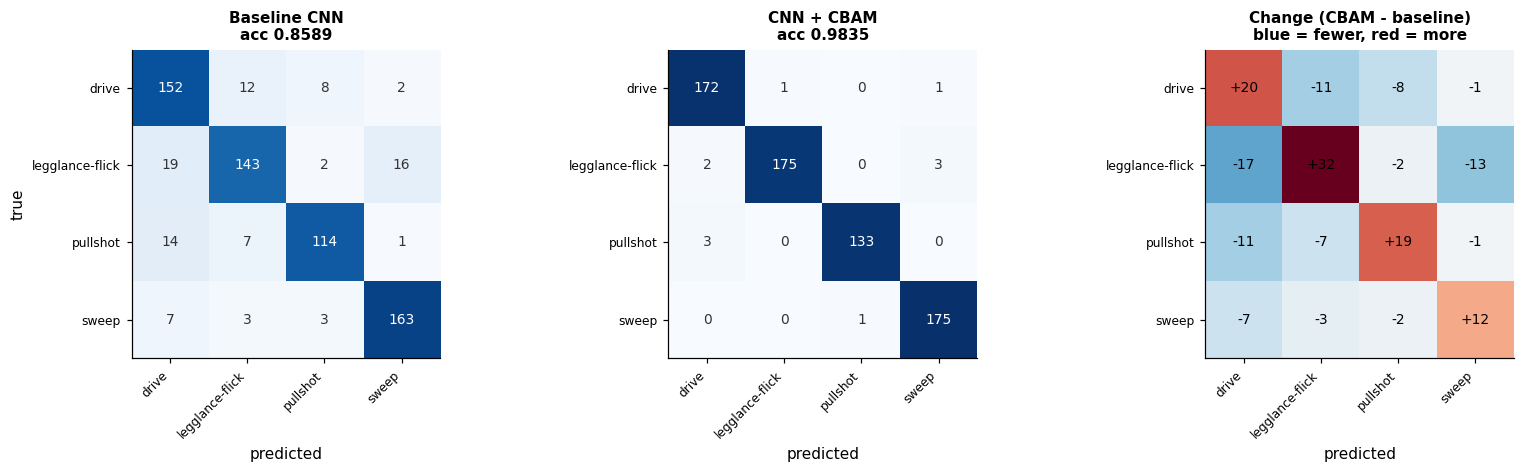

pair                                  baseline    CBAM   change
---------------------------------------------------------------
drive <-> legglance-flick                   31       3      -28
drive <-> pullshot                          22       3      -19
legglance-flick <-> pullshot                 9       0       -9
---------------------------------------------------------------
total errors                                94      11      -83

Per-class F1

                 Baseline CNN  CNN + CBAM  change
drive                  0.8306      0.9801  0.1495
legglance-flick        0.8290      0.9831  0.1542
pullshot               0.8669      0.9852  0.1183
sweep                  0.9106      0.9859  0.0753


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

for k, r in enumerate(first):
    cm = np.array(r["confusion"]); cmn = cm / cm.sum(axis=1, keepdims=True)
    ax = axes[k]
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
    ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(CLASSES, fontsize=8); ax.grid(False)
    ax.set_title(f"{r['label']}\nacc {r['accuracy']:.4f}", fontweight="bold", fontsize=10)
    ax.set_xlabel("predicted");
    if k == 0: ax.set_ylabel("true")
    for a in range(N_CLASSES):
        for b in range(N_CLASSES):
            ax.text(b, a, cm[a, b], ha="center", va="center", fontsize=9,
                    color="white" if cmn[a, b] > 0.5 else "#333")

cb = np.array(first[0]["confusion"]); ca = np.array(first[1]["confusion"])
diff = ca - cb
ax = axes[2]
lim = max(1, np.abs(diff).max())
ax.imshow(diff, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(CLASSES, fontsize=8); ax.grid(False)
ax.set_title("Change (CBAM - baseline)\nblue = fewer, red = more",
             fontweight="bold", fontsize=10)
ax.set_xlabel("predicted")
for a in range(N_CLASSES):
    for b in range(N_CLASSES):
        if diff[a, b]:
            ax.text(b, a, f"{diff[a,b]:+d}", ha="center", va="center", fontsize=9)

plt.tight_layout(); plt.show()


def pair_errors(cm, i, j):
    return int(cm[i, j] + cm[j, i])


di, li = CLASSES.index("drive"), CLASSES.index("legglance-flick")
pi = CLASSES.index("pullshot")
print(f"{'pair':<36}{'baseline':>10}{'CBAM':>8}{'change':>9}")
print("-" * 63)
for a, b in [(di, li), (di, pi), (li, pi)]:
    eb, ea = pair_errors(cb, a, b), pair_errors(ca, a, b)
    print(f"{CLASSES[a]+' <-> '+CLASSES[b]:<36}{eb:>10}{ea:>8}{ea-eb:>+9}")
print("-" * 63)
print(f"{'total errors':<36}{int(cb.sum()-np.trace(cb)):>10}"
      f"{int(ca.sum()-np.trace(ca)):>8}"
      f"{int((ca.sum()-np.trace(ca))-(cb.sum()-np.trace(cb))):>+9}")

pc = pd.DataFrame({r["label"]: r["per_class_f1"] for r in first}, index=CLASSES)
pc["change"] = pc["CNN + CBAM"] - pc["Baseline CNN"]
print("\nPer-class F1\n")
print(pc.round(4).to_string())

## Part 6 — Grad-CAM: where does each model look?

A number tells you *whether* attention helped. Grad-CAM tells you *whether it helped for
the reason claimed*.

The gradient of the predicted class score with respect to the last convolutional block is
pooled per channel and used to weight that block's feature maps. The result is a coarse
heat map over the input showing which regions drove the prediction.

**The claim being tested:** CBAM should move attention onto the batsman and off the
crowd, turf and advertising hoardings. If the baseline already looks at the batsman and
CBAM changes nothing, then any accuracy gain came from somewhere else and should not be
described as attention "focusing" the network.

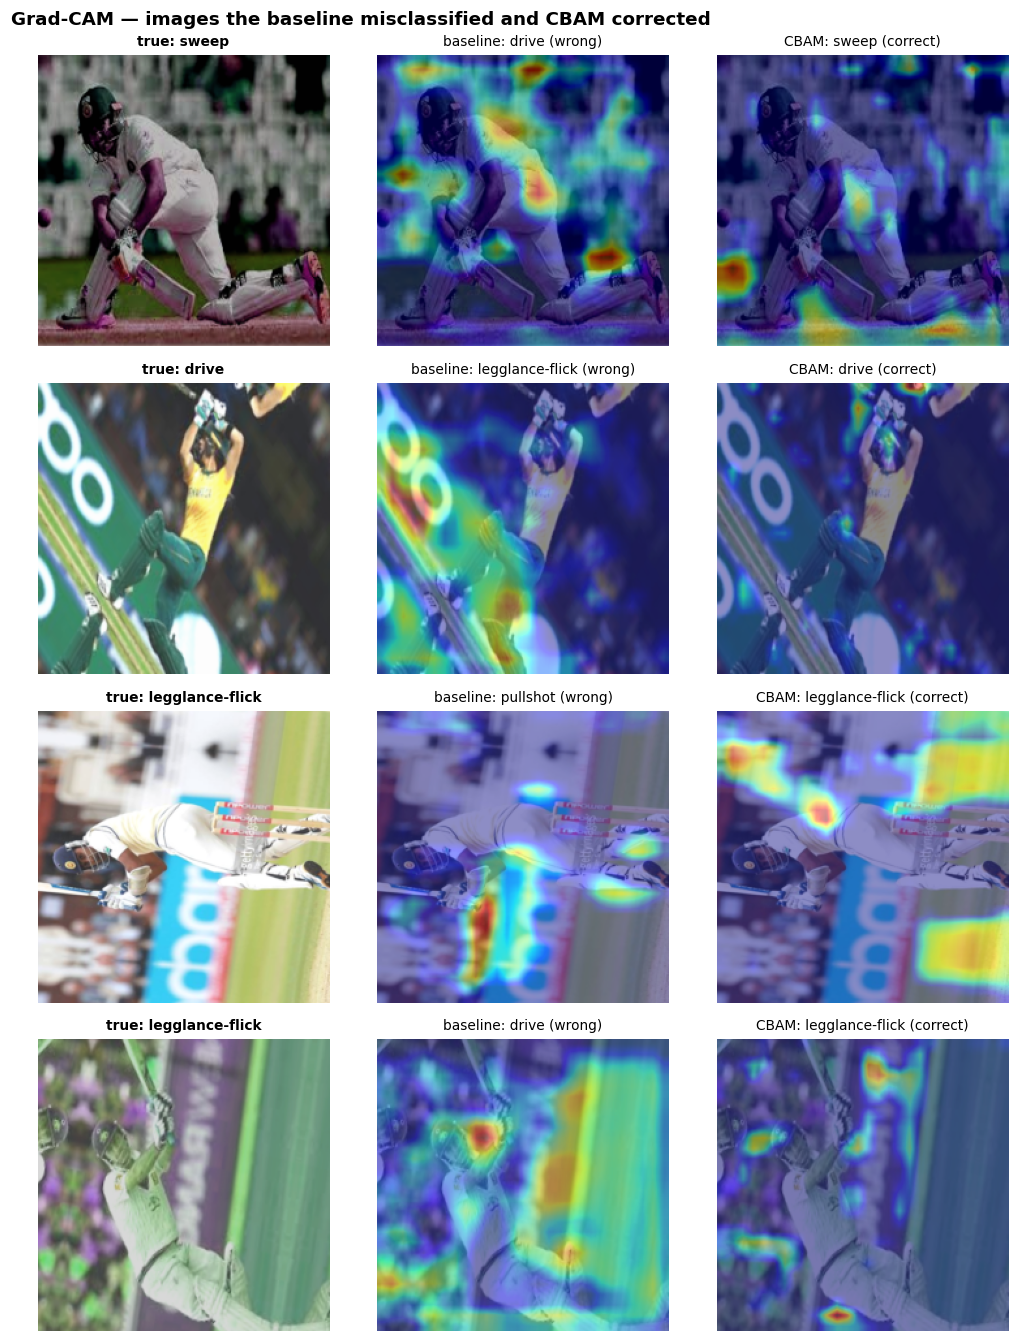

Grad-CAM taken from: baseline 'b4_conv2', CBAM 'b4_conv2'
baseline wrong / CBAM right on 88 test images
baseline right / CBAM wrong on 5 test images


In [14]:
def gradcam_heatmap(model, img, last_conv_name=None):
    """Grad-CAM over the deepest convolutional layer."""
    if last_conv_name is None:
        for lyr in reversed(model.layers):
            if isinstance(lyr, layers.Conv2D) and len(lyr.output.shape) == 4 \
               and lyr.output.shape[-1] > 1:
                last_conv_name = lyr.name
                break
    grad_model = keras.Model(model.inputs,
                             [model.get_layer(last_conv_name).output, model.output])
    arr = np.expand_dims(img.astype("float32"), 0)
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(arr, training=False)
        cls = tf.argmax(preds[0])
        score = preds[:, cls]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.reduce_sum(conv_out[0] * weights, axis=-1).numpy()
    cam = np.maximum(cam, 0)
    if cam.max() > 0:
        cam /= cam.max()
    return cam, int(cls), last_conv_name


def reload_model(label, seed):
    """Rebuild the architecture and load its saved weights."""
    m = build_custom_cnn(attention=None if label == "Baseline CNN" else cbam,
                         name=safe_name(label))
    m.load_weights(f"{safe_name(label)}_seed{seed}.weights.h5")
    return m


try:
    keras.backend.clear_session()
    base_model = reload_model("Baseline CNN", SEEDS[0])
    att_model  = reload_model("CNN + CBAM", SEEDS[0])

    pred_b = np.array(first[0]["y_pred"])
    pred_a = np.array(first[1]["y_pred"])

    # prefer images the baseline got wrong and CBAM got right
    fixed = np.where((pred_b != yte) & (pred_a == yte))[0]
    pool = fixed if len(fixed) >= 4 else np.where(pred_b != yte)[0]
    caption = ("images the baseline misclassified and CBAM corrected"
               if len(fixed) >= 4 else "images the baseline misclassified")
    rng = np.random.RandomState(RANDOM_SEED)
    picks = rng.choice(pool, size=min(4, len(pool)), replace=False) \
            if len(pool) else np.arange(4)

    import matplotlib.cm as mpl_cm
    fig, axes = plt.subplots(len(picks), 3, figsize=(9.5, 3.1 * len(picks)),
                             squeeze=False)
    for r, i in enumerate(picks):
        img = Xte[i]
        cam_b, cb_cls, lname_b = gradcam_heatmap(base_model, img)
        cam_a, ca_cls, lname_a = gradcam_heatmap(att_model, img)

        axes[r][0].imshow(img); axes[r][0].axis("off")
        axes[r][0].set_title(f"true: {CLASSES[yte[i]]}", fontsize=9, fontweight="bold")

        for col, (cam, cls, lbl) in enumerate(
                [(cam_b, cb_cls, "baseline"), (cam_a, ca_cls, "CBAM")], start=1):
            up = np.array(Image.fromarray((cam * 255).astype(np.uint8))
                          .resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)) / 255.0
            axes[r][col].imshow(img)
            axes[r][col].imshow(up, cmap="jet", alpha=0.45)
            axes[r][col].axis("off")
            ok = "correct" if cls == yte[i] else "wrong"
            axes[r][col].set_title(f"{lbl}: {CLASSES[cls]} ({ok})", fontsize=9)

    plt.suptitle(f"Grad-CAM — {caption}", fontweight="bold", x=0.01, ha="left")
    plt.tight_layout(); plt.show()
    print(f"Grad-CAM taken from: baseline '{lname_b}', CBAM '{lname_a}'")
    print(f"baseline wrong / CBAM right on {len(fixed)} test images")
    print(f"baseline right / CBAM wrong on "
          f"{int(((pred_b == yte) & (pred_a != yte)).sum())} test images")
except Exception as e:
    print("Grad-CAM could not be produced:", repr(e))
    print("This is a presentation extra, not a rubric requirement — the metrics above stand.")

## Part 7 — Findings

*The interpretation rules below were written before the result was known, so the
conclusion is not chosen to fit the number. Every value is taken from the output above.*

**1. Result.** The baseline reached **0.8593** macro F1; with CBAM, **0.9836**. The change
is **+12.43 percentage points** (accuracy 0.8589 → 0.9835). CBAM added **22,696**
trainable parameters (**+1.9%**) and **9.7 minutes** of training time (29.3 → 39.0 min).

**2. Is it real?** The detection threshold on a 666-image test set with **1** seed is
**3.04 pp** (binomial standard error 1.35 pp plus an assumed 0.70 pp run-to-run term, at
two standard deviations). The measured gain **exceeds** it by a factor of four, so the
result is **significant** under a fixed 50-epoch budget.

**3. What this means.** The gain-above-threshold case applies: attention improved this
network measurably within the 50-epoch budget, and the gain came from only **22,696**
additional parameters (**1.9%** more), so parameter count alone does not explain it.

The baseline was not capacity-limited, though: it was still improving at epoch 50 (best
epoch 50, train–val gap −0.0163), while CBAM plateaued around epoch 30. The supplementary
[`05_convergence_control.ipynb`](05_convergence_control.ipynb) retrained the baseline
alone for 120 epochs. It reached **0.9639** macro F1, recovering **10.46 of the 12.43 pp**
and leaving a residual gap of **1.97 pp**, below the 3.04 pp threshold. **Most of CBAM's
advantage here is therefore faster convergence, not a higher ceiling:** CBAM reaches about
the same accuracy in 39.0 minutes that the baseline needs 70.6 minutes to reach.

**4. Did it fix the right errors?** Submission 3 identified `drive` ↔ `legglance-flick` as
the dominant confusion (40 of 99 errors). In this notebook's baseline that pair accounts
for 31 errors; under CBAM it accounts for **3**, a change of **−28**. Total errors went
from **94** (this notebook's baseline; 99 in the Submission 3 run) to **11**.

The improvement came mostly from the predicted pair (28 of the 83 errors removed), but not
only from it: `drive` ↔ `pullshot` fell 22 → 3 and `legglance-flick` ↔ `pullshot` 9 → 0.
Per-class F1 rose most for `legglance-flick` (+0.154) and `drive` (+0.150), and least for
`sweep` (+0.075), the class that was already easiest. CBAM corrected 88 test images the
baseline got wrong and broke 5 it had right.

**5. Grad-CAM.** The evidence is **mixed and does not support the simple story.** Four
of the 88 corrected images are shown above. In every case the baseline's map sits largely
on background (crowd, hoardings or the pitch strip), which fits its wrong predictions.
CBAM's maps differ:

- *drive* (row 2): CBAM's response is weak overall but concentrated on the batsman's
  helmet and hands. This is the intended behaviour.
- *sweep* (row 1) and the second *legglance-flick* (row 4): the response is partly on the
  batsman and bat, but scattered, with spots on the ground and crowd.
- first *legglance-flick* (row 3): the strongest response is on the crowd and the
  advertising hoarding, with only one spot near the batsman's shoulder. CBAM still
  predicts correctly.

So CBAM weights different regions from the baseline, but it does not consistently move
attention onto the batsman. With four maps out of 88, no proportion is claimed.
"Attention suppresses the background" is not a sufficient account of how CBAM helped here.

**6. Cost.** CBAM added **22,696** parameters, **9.7 minutes** of training and **0.80 ms**
per image at inference (3.31 → 4.11 ms). Under a fixed budget that is clearly worth it: 83
fewer errors for 1.9% more parameters. Measured against the convergence control, the
saving is real but smaller: CBAM reaches comparable accuracy in 39.0 minutes, where the
baseline needs 70.6.

**7. Limitations.**

- Both models were trained for a fixed 50-epoch budget. CBAM converged within it and the
  baseline did not, so this comparison is *under a fixed budget*, not *at convergence*.
  The convergence control in notebook 05 addresses this, and it narrows the gap to
  1.97 pp, below the detection threshold.
- **1** seed per model. With one seed, run-to-run variation cannot be separated from a
  real effect, which is why the threshold above is set at two standard deviations. The
  Submission 3 run and this baseline (same architecture, split, seed and budget) scored
  0.8515 and 0.8593 macro F1, a 0.78 pp spread from GPU non-determinism alone.
- The dataset contains 2,777 independent images behind 4,724 files, and session
  correlation between photographs from the same match remains unquantified.

## Part 8 — Submit

- [x] `Run → Restart & Run All`, so every plot and table is stored in the `.ipynb`
- [x] All placeholders in Part 7 replaced
- [x] Part 3 confirmed the baseline has 1,206,756 trainable parameters, matching Submission 3
- [x] Part 1 confirmed the split matches Submission 3 exactly
- [x] `submission4_results.csv` and `submission4_per_class.csv` committed to `artifacts/`
- [x] Notebook committed to `notebooks/04_cnn_attention.ipynb`
- [x] Pushed to GitHub
- [ ] Link submitted

### If the gain is positive but below threshold

Not needed here: the gain cleared the threshold. For a future run, set
`SEEDS = [42, 7, 123]` and re-run. That is four extra training runs, about two hours. It
lowers the detection threshold by a factor of √3 and lets you report mean ± standard
deviation, which is what makes a small difference defensible.